## Data loading, and feature and data descriptions

In [130]:
import scipy.io
import pandas as pd
import os

# 1. Load the .mat file
# Using os.getcwd() to ensure 'pwd' is handled correctly
path = os.path.join(os.getcwd(), '1. BatteryAgingARC-FY08Q4/B0005.mat')
mat = scipy.io.loadmat(path)

battery_id = 'B0005'
cycles = mat[battery_id][0, 0]['cycle'][0]

# 2. Initialize lists to hold data for each type
charge_data = []
discharge_data = []
impedance_data = []

# 3. Iterate through all cycles and extract values
for i, cycle in enumerate(cycles):
    cycle_type = cycle['type'][0]
    # 'data' is where the actual measurements live
    data = cycle['data'][0, 0]
    
    # Create a base dictionary with the cycle index
    row = {'cycle_index': i}
    
    # Extract measurement values
    # Note: NASA data often stores these as arrays within the struct
    for field in data.dtype.names:
        val = data[field][0]
        # Many fields are arrays of time-series data. 
        # For a summary table, we usually take the first value or the mean.
        # If you want the full time series, you'd need a different approach.
        row[field] = val[0] if len(val) > 0 else None # type: ignore

    # Append to the correct list
    if cycle_type == 'charge':
        charge_data.append(row)
    elif cycle_type == 'discharge':
        discharge_data.append(row)
    elif cycle_type == 'impedance':
        impedance_data.append(row)

# 4. Create the 3 DataFrames
df_charge = pd.DataFrame(charge_data)
df_discharge = pd.DataFrame(discharge_data)
df_impedance = pd.DataFrame(impedance_data)

# 5. Display the first few rows of each
print("--- CHARGE DATAFRAME ---")
print(f"features: {df_charge.columns.tolist()}. \n Total features: {len(df_charge.columns.tolist())}")
print(df_charge.head())

print("\n--- DISCHARGE DATAFRAME ---")
print(f"features: {df_discharge.columns.tolist()}. \n Total features: {len(df_discharge.columns.tolist())}")
print(df_discharge.head())

print("\n--- IMPEDANCE DATAFRAME ---")
print(f"features: {df_impedance.columns.tolist()}. \n Total features: {len(df_impedance.columns.tolist())}")
print(df_impedance.iloc[:, [0,6,7]].head())




--- CHARGE DATAFRAME ---
features: ['cycle_index', 'Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_charge', 'Voltage_charge', 'Time']. 
 Total features: 7
   cycle_index  Voltage_measured  Current_measured  Temperature_measured  \
0            0          3.873017         -0.001201             24.655358   
1            2          3.325055          0.000302             29.341851   
2            4          3.352604          0.001990             29.553301   
3            6          3.378799         -0.002266             29.456340   
4            8          3.372871         -0.000503             29.481334   

   Current_charge  Voltage_charge  Time  
0           0.000           0.003   0.0  
1          -0.002           0.003   0.0  
2           0.000           0.003   0.0  
3           0.000           0.003   0.0  
4           0.000           0.003   0.0  

--- DISCHARGE DATAFRAME ---
features: ['cycle_index', 'Voltage_measured', 'Current_measured', 'Temperature_mea

### Key Takeaway for Analysis:

**For State of Health (SOH):** You will primarily use the 7 features from the Discharge cycles, as this is the only section where the Capacity (your target variable) is recorded.


### Insights from Impedance Data:

1. **Electrolyte Resistance ($R_e$):** This represents the resistance of the electrolyte and the separator.

    - In the table, you can see it starts around 0.0447 $\Omega$ and increases as the battery ages (reaching 0.0500 $\Omega$ near the end). This increase is a primary sign of internal degradation.
    
2. **Charge Transfer Resistance ($R_{ct}$):** This represents the resistance to the flow of ions at the electrode-electrolyte interface.

    - $R_{ct}$ is highly sensitive to the battery's health; a significant rise in this value usually correlates with a drop in capacity.





## Transient Response

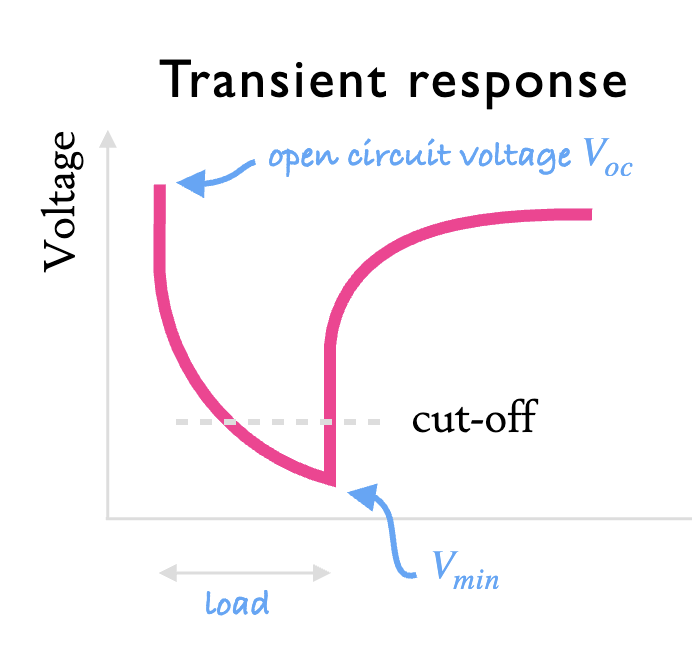


Think of a battery not just as a tank of energy, but as a chemical engine. When you ask it to work (by applying a load), it doesn't just "hand over" power instantly; it goes through a struggle. That struggle is what we call the Transient Response.

This figure shows exactly what happens to the battery's voltage from the moment you turn it on to the moment you turn it off.

- 1. **V_oc (Open Circuit Voltage)**

This is the starting point. The battery is at rest, and no current is flowing.

The State: This is the "pure" voltage of the battery.

The Beginner View: Think of this as the height of water in a tank before you open the faucet.

- 2. **The Initial Drop (Ohmic Drop)**

The moment the load starts, you see a sharp, almost vertical drop.

The Cause: This is caused by Ohmic Resistance. It is the physical resistance of the battery's internal metal parts and the liquid electrolyte.

Why it matters: As a battery gets older and "unhealthy," this vertical drop becomes much deeper.

- 3. **The Downward Curve (The Work Phase)**

As the load continues, the voltage keeps sliding down. This is where Activation and Concentration Polarization happen.

Activation Polarization: The "cost" of getting the chemical reactions started at the electrodes.

Concentration Polarization: As you pull energy out, the lithium ions get "crowded" near the electrodes. They can't move fast enough to keep up with the demand, causing the voltage to sag further.

- 4. **V_min and the "Cut-off"** 


The V_min is the lowest point the voltage reaches before the load is removed.

The Cut-off: This dashed line is the "safety limit." In your NASA data, this is usually 2.7V. If you go below this, you risk permanently damaging the battery's chemistry.

- 5. **The Recovery (Voltage Relaxation)**
When the load is removed (the end of the "load" arrow), the voltage "bounces back" upward.

The Physics: This is the battery "catching its breath." Now that the current has stopped, the crowded lithium ions have time to spread out and balance themselves again.

**The Shape:** Notice it doesn't jump back to V_oc nstantly. It curves slowly. The speed of this curve tells researchers how efficient the battery's internal chemistry still is.

Open Circuit Voltage: 4.19 V, Min Voltage: 2.61 V, Max Voltage: 4.19 V


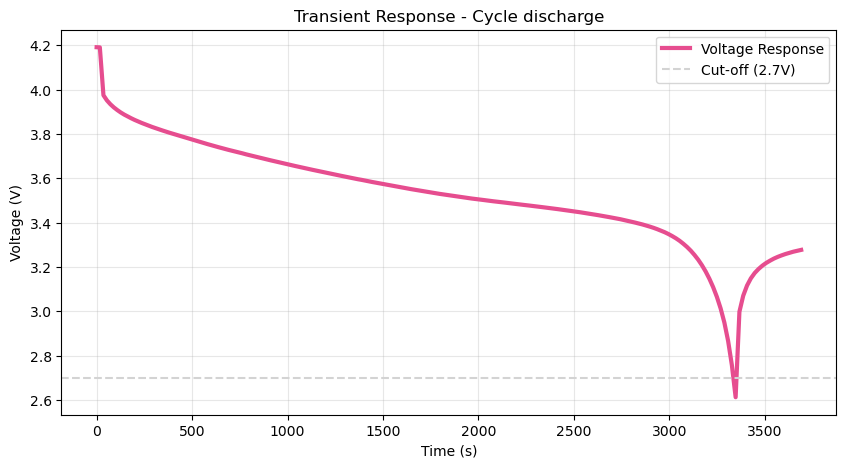

In [46]:
import matplotlib.pyplot as plt

# 1. Pick a specific discharge cycle (e.g., the first one available)
# We use cycles[index] directly to get the full time-series 'data'
cycle_to_plot = cycles[1] # Usually index 1 is the first discharge in B0005
data = cycle_to_plot['data'][0, 0]

# 2. Extract the time-series arrays
time = data['Time'][0]
voltage = data['Voltage_measured'][0]

v_oc = voltage[0]
v_min = voltage.min()
v_max = voltage.max()
print(f"Open Circuit Voltage: {v_oc:.2f} V, Min Voltage: {v_min:.2f} V, Max Voltage: {v_max:.2f} V")

# 3. Create the plot
plt.figure(figsize=(10, 5))
plt.plot(time, voltage, color='#e64d8f', linewidth=3, label='Voltage Response')

# 4. Replicate the styling from your image
plt.axhline(y=2.7, color='lightgray', linestyle='--', label='Cut-off (2.7V)') # B0005 cutoff is 2.7V
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.title(f'Transient Response - Cycle {cycle_to_plot["type"][0]}')
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

1. The Instant "Ohmic" Drop

    - Observation: At the very start (Time = 0), the voltage drops instantly from 4.2V to approximately 3.95V.
    
    - Inference: This vertical line is the Ohmic Drop. It tells us the "internal resistance" of the battery's physical parts (metal tabs and electrolyte liquid).
    
2. The Discharge Slope (The Long Glide)
    -   Observation: Between 100s and 3000s, the voltage slides gradually from 3.9V down to 3.4V.
    
    - Inference: This represents the Concentration Polarization—the "traffic jam" of lithium ions swimming through the liquid.
    
3. The End-of-Discharge "Dip"
    
    -   Observation: At roughly 3350 seconds, the voltage plummets past the 2.7V cut-off line, hitting a minimum ($V_{min}$) of about 2.6V.
    
    -   Inference: This is the point where the battery is "empty." The steepness here shows that the chemical reaction has exhausted all available ions at the electrode surface.
    
4. The Voltage Recovery (The Rebound)

    -   Observation: After the load is removed (the lowest point), the voltage begins to curve back up toward 3.3V.

    -   Inference: This is Voltage Relaxation. Now that you aren't pulling energy out, the ions are "calming down" and spreading out evenly again.

**Transient Response: Difference between first discharge and last discharge cycle**

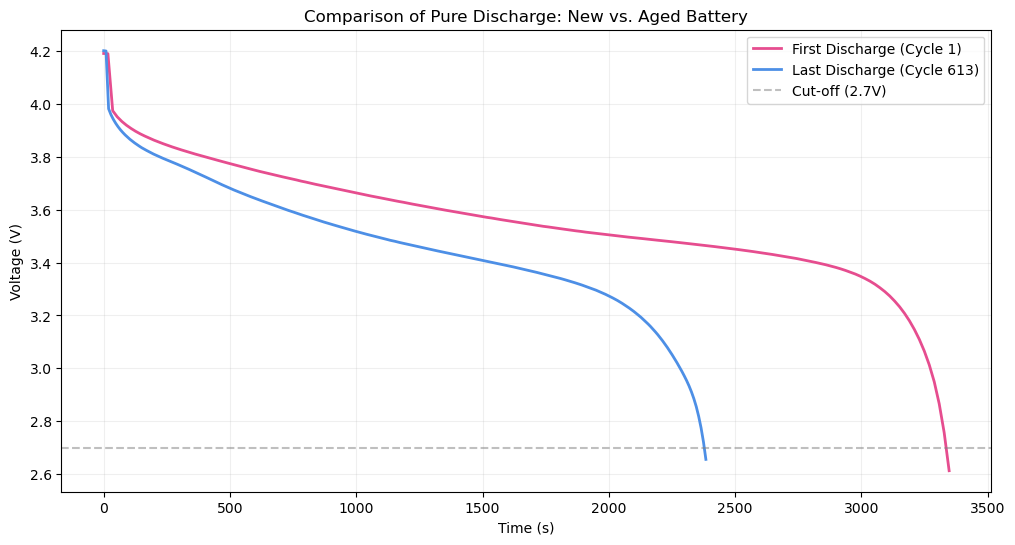

In [57]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Identify all discharge indices
discharge_indices = [i for i, c in enumerate(cycles) if c['type'][0] == 'discharge']
first_idx = discharge_indices[0]
last_idx = discharge_indices[-1]

plt.figure(figsize=(12, 6))

# Helper function to "cut" the data at the minimum voltage point
def get_discharge_only(cycle_data):
    time = cycle_data['Time'][0]
    voltage = cycle_data['Voltage_measured'][0]
    
    # Find the index of the minimum voltage (the "dip")
    # This is exactly when the load was turned off
    stop_idx = np.argmin(voltage) 
    
    # Return only the data UP TO that point
    return time[:stop_idx+1], voltage[:stop_idx+1]

# 2. Plot First Discharge (Cut off at relaxation)
time_f, volt_f = get_discharge_only(cycles[first_idx]['data'][0, 0])
plt.plot(time_f, volt_f, color='#e64d8f', linewidth=2, label=f'First Discharge (Cycle {first_idx})')

# 3. Plot Last Discharge (Cut off at relaxation)
time_l, volt_l = get_discharge_only(cycles[last_idx]['data'][0, 0])
plt.plot(time_l, volt_l, color='#4d8fe6', linewidth=2, label=f'Last Discharge (Cycle {last_idx})')

# 4. Styling
plt.axhline(y=2.7, color='gray', linestyle='--', alpha=0.5, label='Cut-off (2.7V)')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.title('Comparison of Pure Discharge: New vs. Aged Battery')
plt.legend()
plt.grid(True, alpha=0.2)

plt.show()

1. The Shrinking Life (Capacity Fade)

    - Observation: The pink line (New) lasts for about 3,300 seconds before it hits the bottom. The blue line (Old) only lasts about 2,400 seconds.

    - Inference: This is Capacity Fade. The battery has lost roughly 27% of its "stamina" because the electrodes can no longer hold as many lithium ions as they once did.

2. The Deeper Drop (Higher Resistance)

    - Observation: Look at the very start (Time = 0). The blue line drops lower and faster than the pink line.

    - Inference: This is the Ohmic Drop. It proves the battery's internal "friction" (resistance) has increased. The "pipes" inside the battery are now more clogged or worn out, making it harder for electrons to flow.

3. Voltage Sag

    - Observation: Throughout the entire discharge, the blue line stays consistently lower than the pink line.

    - Inference: This is called Voltage Sag. Because the internal resistance is higher, the battery has to "work harder" to give you the same power, which causes the voltage to stay depressed. This is why an old phone might feel slower or shut down unexpectedly under a heavy load.

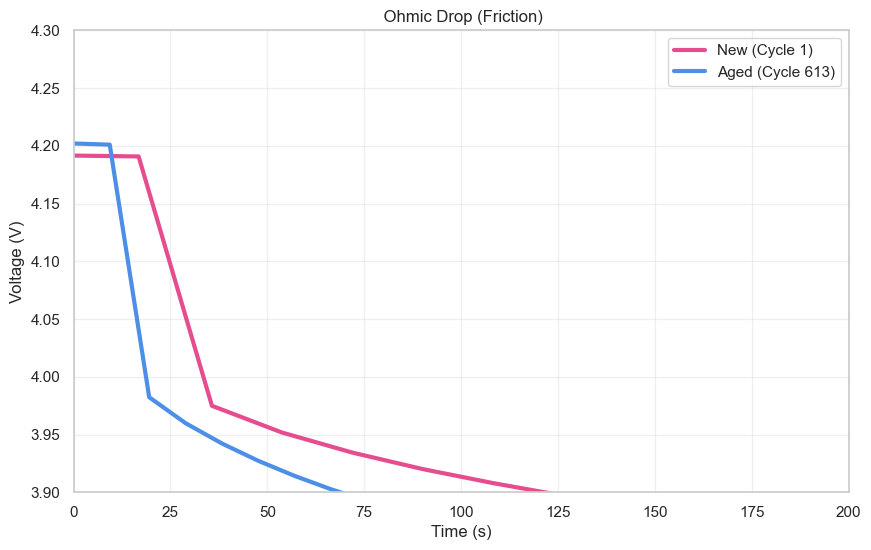

In [134]:
plt.figure(figsize=(10, 6))

# Plotting First Cycle
plt.plot(data_first['Time'][0], data_first['Voltage_measured'][0], 
         color='#e64d8f', linewidth=3, label='New (Cycle 1)')

# Plotting Last Cycle
plt.plot(data_last['Time'][0], data_last['Voltage_measured'][0], 
         color='#4d8fe6', linewidth=3, label='Aged (Cycle 613)')


plt.xlim(0, 200) 

plt.ylim(3.9, 4.3) 
# ------------------------------

plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.title(' Ohmic Drop (Friction)')
plt.legend()
plt.grid(True, alpha=0.3)


## Identifying degradation trends, 


EDA completed successfully.


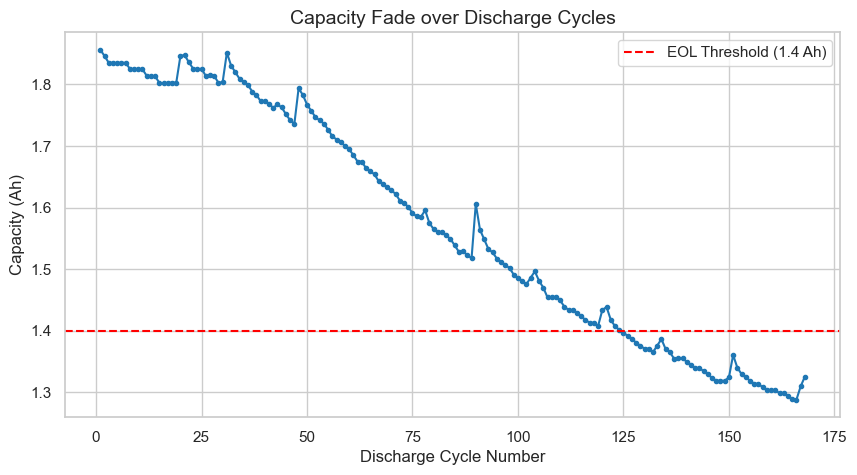

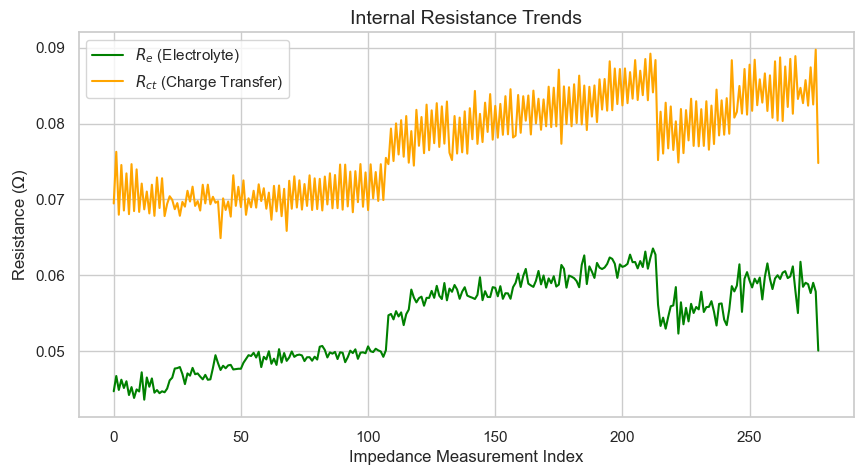

In [103]:
import scipy.io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Set plotting style
sns.set_theme(style="whitegrid")

# 1. Data Extraction and Structuring
path = os.path.join(os.getcwd(), '1. BatteryAgingARC-FY08Q4/B0005.mat')
mat = scipy.io.loadmat(path)
battery_id = 'B0005'
cycles = mat[battery_id][0, 0]['cycle'][0]

# Lists to hold cycle-level summary data
summary_data = []
# Dictionary to hold time-series data for specific discharge cycles
discharge_profiles = {}

discharge_count = 0
for i, cycle in enumerate(cycles):
    c_type = cycle['type'][0]
    amb_temp = cycle['ambient_temperature'][0, 0]
    t_vec = cycle['time'][0]
    start_time = datetime(int(t_vec[0]), int(t_vec[1]), int(t_vec[2]), 
                          int(t_vec[3]), int(t_vec[4]), int(t_vec[5]))
    
    data = cycle['data'][0, 0]
    
    # Extract Summary Info
    row = {
        'cycle_index': i + 1,
        'type': c_type,
        'ambient_temp': amb_temp,
        'start_time': start_time
    }
    
    if c_type == 'discharge':
        discharge_count += 1
        row['capacity'] = data['Capacity'][0, 0]
        row['max_temp'] = np.max(data['Temperature_measured'][0])
        row['min_voltage'] = np.min(data['Voltage_measured'][0])
        
        # Store full profile for specific milestones (Start, Mid, End)
        # We'll pick roughly cycles 1, 84, 168 (of discharge)
        if discharge_count in [1, 84, 168]:
            df_profile = pd.DataFrame({
                'time': data['Time'][0],
                'voltage': data['Voltage_measured'][0],
                'current': data['Current_measured'][0],
                'temp': data['Temperature_measured'][0]
            })
            discharge_profiles[f'Cycle_{discharge_count}'] = df_profile

    elif c_type == 'impedance':
        row['re'] = data['Re'][0, 0]
        row['rct'] = data['Rct'][0, 0]
    
    summary_data.append(row)

df_summary = pd.DataFrame(summary_data)
df_discharge = df_summary[df_summary['type'] == 'discharge'].copy()
df_discharge['discharge_cycle'] = range(1, len(df_discharge) + 1)
df_impedance = df_summary[df_summary['type'] == 'impedance'].dropna(subset=['re']).copy()

# 2. Visualization
# Plot 1: Capacity Degradation
plt.figure(figsize=(10, 5))
plt.plot(df_discharge['discharge_cycle'], df_discharge['capacity'], marker='o', markersize=3, linestyle='-', color='tab:blue')
plt.axhline(y=1.4, color='red', linestyle='--', label='EOL Threshold (1.4 Ah)')
plt.title('Capacity Fade over Discharge Cycles', fontsize=14)
plt.xlabel('Discharge Cycle Number')
plt.ylabel('Capacity (Ah)')
plt.legend()
plt.savefig('eda_capacity_fade.png')


# Plot 3: Internal Resistance Trends
plt.figure(figsize=(10, 5))
plt.plot(range(len(df_impedance)), df_impedance['re'], label='$R_e$ (Electrolyte)', color='green')
plt.plot(range(len(df_impedance)), df_impedance['rct'], label='$R_{ct}$ (Charge Transfer)', color='orange')
plt.title('Internal Resistance Trends', fontsize=14)
plt.xlabel('Impedance Measurement Index')
plt.ylabel('Resistance ($\Omega$)')
plt.legend()
plt.savefig('eda_impedance_trends.png')


# Export structured summary
df_summary.to_csv('battery_eda_summary.csv', index=False)
print("EDA completed successfully.")


- Capacity Fade & Regeneration

The capacity plot shows a clear downward trend but is characterized by "Regeneration Spikes".

**Observation:** After periods of inactivity (rest), the capacity temporarily increases.

**Impact:** This makes linear models less effective and suggests that Rest Time is a valuable hidden feature for Machine Learning.


## Correlation between different features


Correlation Matrix:
             Cycle  Capacity       Rct  Max_Temp        Re
Cycle     1.000000 -0.987739  0.908870  0.914857  0.879127
Capacity -0.987739  1.000000 -0.935829 -0.935272 -0.899751
Rct       0.908870 -0.935829  1.000000  0.886144  0.945753
Max_Temp  0.914857 -0.935272  0.886144  1.000000  0.900880
Re        0.879127 -0.899751  0.945753  0.900880  1.000000


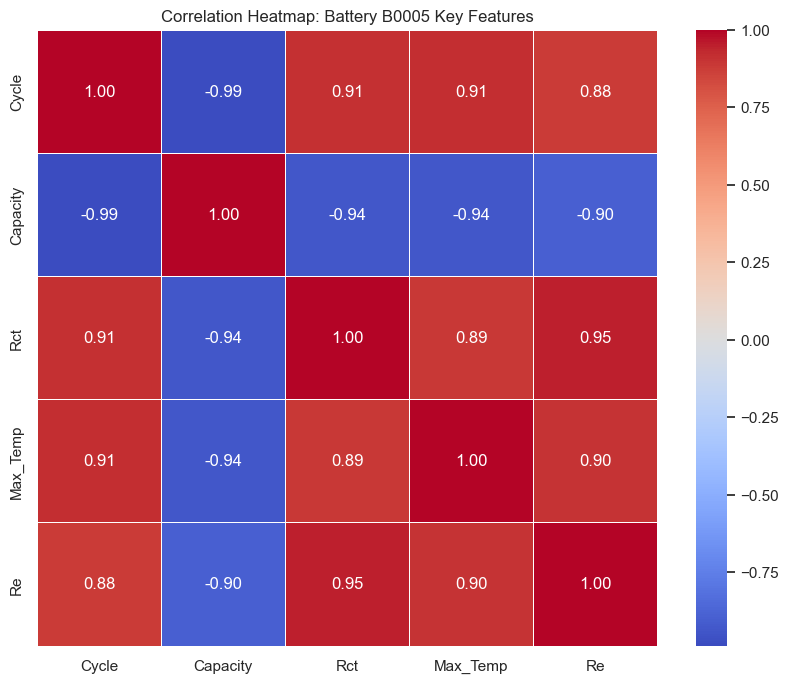

In [69]:
import scipy.io
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load the .mat file
path = os.path.join(os.getcwd(), '1. BatteryAgingARC-FY08Q4/B0005.mat')
mat = scipy.io.loadmat(path)
battery_id = 'B0005'
cycles = mat[battery_id][0, 0]['cycle'][0]

# 2. Extract relevant data points
discharge_data = []
impedance_data = []

for i, cycle in enumerate(cycles):
    c_type = cycle['type'][0]
    data = cycle['data'][0, 0]
    
    if c_type == 'discharge':
        cap = data['Capacity'][0, 0]
        max_temp = np.max(data['Temperature_measured'][0])
        discharge_data.append({
            'overall_index': i,
            'Capacity': cap,
            'Max_Temp': max_temp
        })
    elif c_type == 'impedance':
        re = data['Re'][0, 0]
        rct = data['Rct'][0, 0]
        impedance_data.append({
            'overall_index': i,
            'Re': re,
            'Rct': rct
        })

df_dis = pd.DataFrame(discharge_data)
df_imp = pd.DataFrame(impedance_data)

# 3. Align data
# Since discharge and impedance cycles are interleaved, we use merge_asof
# to find the nearest impedance values for each discharge cycle.
df_dis = df_dis.sort_values('overall_index')
df_imp = df_imp.sort_values('overall_index')

# Aligning impedance values to the nearest preceding/succeeding discharge cycle
df_merged = pd.merge_asof(df_dis, df_imp, on='overall_index', direction='nearest')

# Add a simple Cycle count (1, 2, 3...) to represent aging
df_merged['Cycle'] = range(1, len(df_merged) + 1)

# 4. Filter for requested columns
heatmap_df = df_merged[['Cycle', 'Capacity', 'Rct', 'Max_Temp', 'Re']]

# 5. Calculate correlation matrix
corr_matrix = heatmap_df.corr()

# 6. Plotting
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap: Battery B0005 Key Features')
plt.savefig('battery_heatmap.png')

print("Correlation Matrix:")
print(corr_matrix)

Conclusions from the Heatmap Relationships:

-  Cycle vs. Capacity ($\approx -0.99$):

    - **Finding:** An almost perfect negative correlation.

    - **Conclusion:** This confirms that the battery is steadily losing capacity as the number of cycles increases. It is the clearest indicator of "Aging."
    
- $R_{ct}$ vs. Capacity ($\approx -0.94$):

    - **Finding:** Strong negative correlation.
    
    - **Conclusion:** As the Charge Transfer Resistance ($R_{ct}$) increases due to internal chemical "crusting" (SEI layer growth), the Capacity drops. This shows $R_{ct}$ is a powerful physical predictor of health.
    
- Max Temp vs. Capacity ($\approx -0.94$):
    
    - **Finding:** Strong negative correlation.
    - **Conclusion:** As capacity fades, the battery gets hotter during use. This is because a degraded battery is less efficient and wastes more energy as heat.

- $R_e$ vs. Capacity ($\approx -0.90$):

    - **Finding:** Strong negative correlation.
    
    - **Conclusion:** While $R_e$ (electrolyte resistance) also increases as capacity drops, its impact is often slightly less than $R_{ct}$ in this specific battery. However, it still shows that the internal "liquids" are degrading alongside the "solids."

### Relationship between $R_{ct}$ (Charge Transfer Resistance) and Capacity 

Correlation between Capacity and Rct: -0.9358287334010723


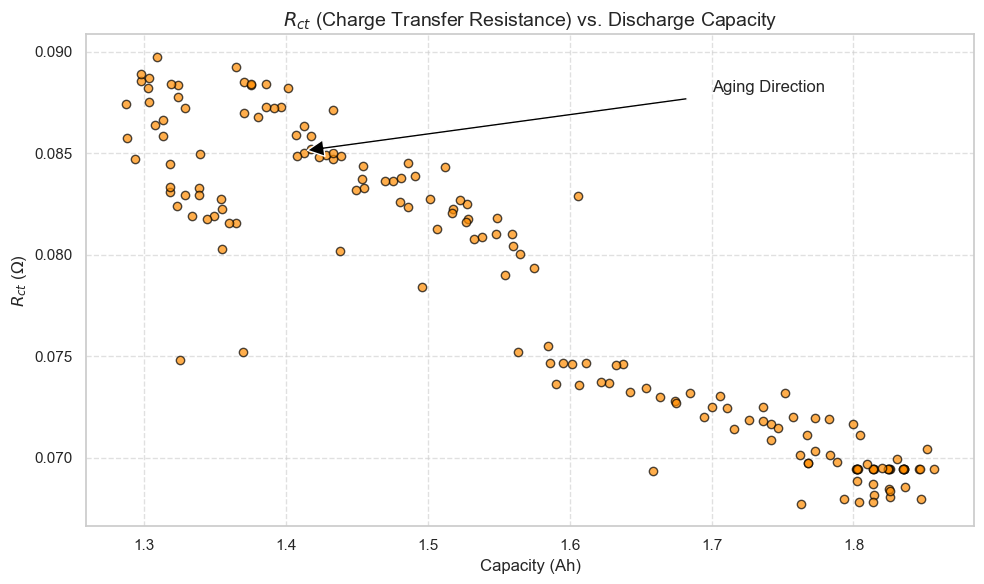

In [70]:
import scipy.io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the .mat file
path = os.path.join(os.getcwd(), '1. BatteryAgingARC-FY08Q4/B0005.mat')
mat = scipy.io.loadmat(path)
cycles = mat['B0005'][0, 0]['cycle'][0]

discharge_data = []
impedance_data = []

# Extract data
for i, cycle in enumerate(cycles):
    c_type = cycle['type'][0]
    data = cycle['data'][0, 0]
    
    if c_type == 'discharge':
        if 'Capacity' in data.dtype.names:
            discharge_data.append({
                'index': i,
                'Capacity': data['Capacity'][0, 0]
            })
    elif c_type == 'impedance':
        if 'Rct' in data.dtype.names:
            impedance_data.append({
                'index': i,
                'Rct': data['Rct'][0, 0]
            })

df_dis = pd.DataFrame(discharge_data)
df_imp = pd.DataFrame(impedance_data)

# Align the data using merge_asof
# We find the nearest impedance measurement for each discharge measurement
df_merged = pd.merge_asof(df_dis.sort_values('index'), 
                          df_imp.sort_values('index'), 
                          on='index', 
                          direction='nearest')

# Plotting Rct vs. Capacity
plt.figure(figsize=(10, 6))
plt.scatter(df_merged['Capacity'], df_merged['Rct'], color='darkorange', edgecolors='black', alpha=0.7)
plt.title('$R_{ct}$ (Charge Transfer Resistance) vs. Discharge Capacity', fontsize=14)
plt.xlabel('Capacity (Ah)', fontsize=12)
plt.ylabel('$R_{ct}$ ($\Omega$)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# Adding an annotation to show the direction of aging
plt.annotate('Aging Direction', xy=(1.4, 0.085), xytext=(1.7, 0.088),
             arrowprops=dict(facecolor='black', shrink=0.05, width=2),
             fontsize=12)

plt.tight_layout()
plt.savefig('rct_vs_capacity.png')

# Output correlation for confirmation in text
correlation = df_merged['Capacity'].corr(df_merged['Rct'])
print(f"Correlation between Capacity and Rct: {correlation}")

### $R_{ct}$ vs. Capacity Analysis

As you can see in the plot, there is a very **strong inverse relationship** between these two variables.

- **The Trend:** As the Capacity (Ah) moves from right to left (decreasing from 1.85 Ah to 1.3 Ah), the $R_{ct}$ ($\Omega$) moves from bottom to top (increasing from 0.065 $\Omega$ to 0.09 $\Omega$).
    
- **Correlation Score:** The correlation coefficient is approximately $-0.936$. This confirms that they track each other almost perfectly, just in opposite directions.
    
- **Physical Meaning:** It proves that the loss of capacity is physically driven by the increase in internal resistance. As the chemical "toll booths" ($R_{ct}$) become more congested with age, the battery's ability to hold and deliver charge (Capacity) drops in tandem.

## State of Health Prediction (SOH)

State of Health (SOH) prediction is typically treated as a Supervised Regression problem. In the context of this dataset, SOH is usually defined as the ratio of the current capacity to the initial capacity:

$$SOH = \frac{Capacity_{current}}{Capacity_{initial}}$$

Here is a step-by-step guide and the code to perform SOH prediction.

- 1. The SOH Prediction WorkflowData Extraction: Pull the Capacity and Cycle index from the discharge cycles.

- 2. Feature Engineering: Since simple cycle numbers don't capture the whole story, researchers often extract features like:
        - Time to discharge: The time it takes for the voltage to drop from 4.2V to a specific threshold (e.g., 3.5V).
        
        - Internal Resistance: Calculated from the impedance cycles or voltage drop at the start of discharge.
        
        - Temperature: Peak temperature reached during discharge.

- 3. Model Selection: While Linear Regression is a baseline, models like Support Vector Regression (SVR), Gaussian Process Regression (GPR), or LSTM (Deep Learning) are more common due to the non-linear nature of battery aging.

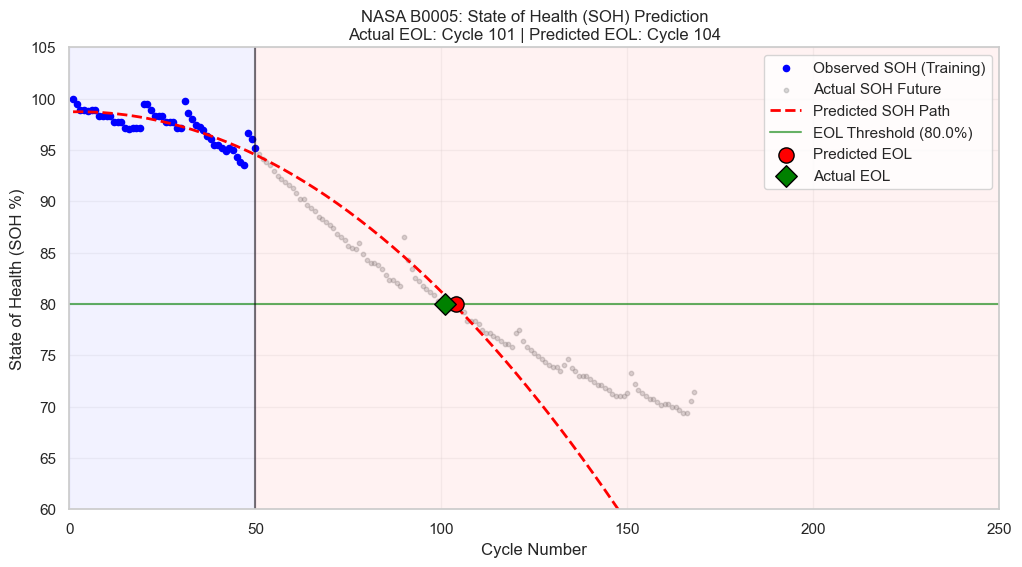

The battery started at 100% SOH.
It hit the 80% SOH threshold at Cycle 101.


In [82]:
import scipy.io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Load and Extract Data
path = os.path.join(os.getcwd(), '1. BatteryAgingARC-FY08Q4/B0005.mat')
mat = scipy.io.loadmat(path)
cycles = mat['B0005'][0, 0]['cycle'][0]

capacity, cycle_id = [], []
for i, cycle in enumerate(cycles):
    if cycle['type'][0] == 'discharge':
        cap = cycle['data'][0, 0]['Capacity'][0, 0]
        capacity.append(cap)
        cycle_id.append(len(cycle_id) + 1)

df = pd.DataFrame({'Cycle': cycle_id, 'Capacity': capacity})

# --- SOH CALCULATION ---

initial_capacity = df['Capacity'].iloc[0] 
df['SOH'] = (df['Capacity'] / initial_capacity) * 100

# Define Failure Threshold in SOH percentage (70% is standard)
soh_threshold = 80.0 

# --- Find Actual Failure Cycle (where SOH <= 70) ---
actual_failure_df = df[df['SOH'] <= soh_threshold]
actual_soh_failure = actual_failure_df['Cycle'].iloc[0] if not actual_failure_df.empty else None

# 2. Setup Training (Learning from the first 50 cycles)
train_limit = 50 
X = df[['Cycle']].values
y_soh = df['SOH'].values # We are now training on SOH % directly
X_train, y_train = X[:train_limit], y_soh[:train_limit]

# 3. Create the Polynomial Model
poly_feat = PolynomialFeatures(degree=2)
X_train_poly = poly_feat.fit_transform(X_train)
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

# 4. Predict the Future SOH
X_future = np.array(range(1, 300)).reshape(-1, 1)
y_future_soh = poly_model.predict(poly_feat.transform(X_future))

# Find the PREDICTED Failure Cycle (where predicted SOH hits 70%)
pred_idx = np.where(y_future_soh <= soh_threshold)[0]
pred_soh_failure = X_future[pred_idx[0]][0] if len(pred_idx) > 0 else 0

# 5. Plotting SOH (%)
plt.figure(figsize=(12, 6))

# Observed & Future Actual SOH
plt.scatter(X[:train_limit], y_soh[:train_limit], color='blue', s=20, label='Observed SOH (Training)')
plt.scatter(X[train_limit:], y_soh[train_limit:], color='gray', s=10, alpha=0.3, label='Actual SOH Future')

# Model SOH Prediction Line
plt.plot(X_future, y_future_soh, color='red', linestyle='--', linewidth=2, label='Predicted SOH Path')

# Failure Threshold Line (at 70%)
plt.axhline(y=soh_threshold, color='green', linestyle='-', alpha=0.6, label=f'EOL Threshold ({soh_threshold}%)')

# Predicted vs Actual Points
plt.scatter(pred_soh_failure, soh_threshold, color='red', s=120, edgecolors='black', zorder=5, label='Predicted EOL')
if actual_soh_failure:
    plt.scatter(actual_soh_failure, soh_threshold, color='green', marker='D', s=120, edgecolors='black', zorder=5, label='Actual EOL')

# Dividers & Styling
plt.axvline(x=train_limit, color='black', alpha=0.5)
plt.fill_betweenx([50, 110], 0, train_limit, color='blue', alpha=0.05)
plt.fill_betweenx([50, 110], train_limit, 300, color='red', alpha=0.05)

plt.xlim(0, 250); plt.ylim(60, 105) # Focus on the 100% to 60% SOH range
plt.xlabel('Cycle Number'); plt.ylabel('State of Health (SOH %)')
plt.title(f'NASA B0005: State of Health (SOH) Prediction\nActual EOL: Cycle {actual_soh_failure} | Predicted EOL: Cycle {pred_soh_failure}')
plt.legend(); plt.grid(True, alpha=0.2)
plt.show()

print(f"The battery started at 100% SOH.")
print(f"It hit the 80% SOH threshold at Cycle {actual_soh_failure}.")

## EOL Prediction

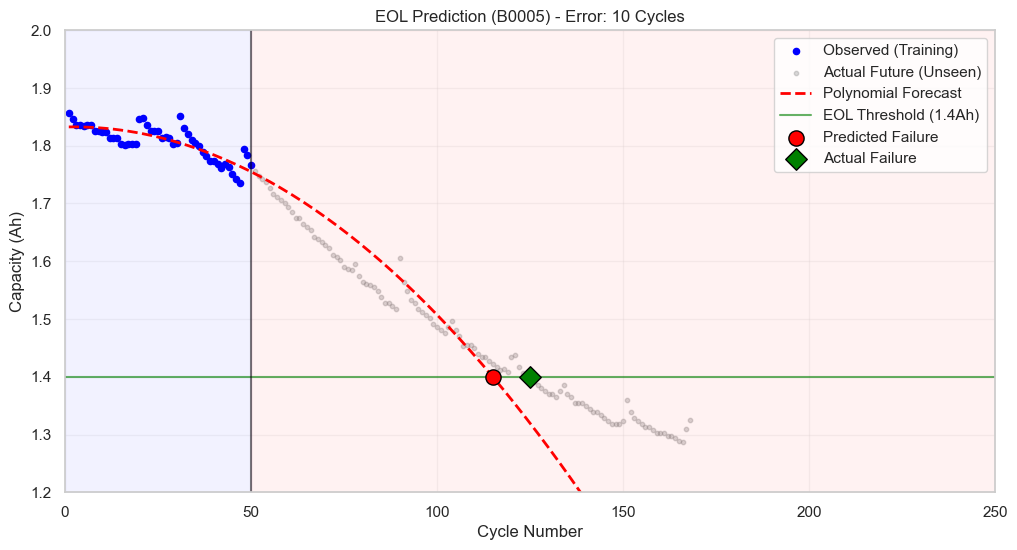

Predicted Failure: Cycle 115
Actual Failure: Cycle 125


In [79]:
import scipy.io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Load and Extract Data (Keeping your extraction logic)
path = os.path.join(os.getcwd(), '1. BatteryAgingARC-FY08Q4/B0005.mat')
mat = scipy.io.loadmat(path)
cycles = mat['B0005'][0, 0]['cycle'][0]

capacity, cycle_id = [], []
for i, cycle in enumerate(cycles):
    if cycle['type'][0] == 'discharge':
        cap = cycle['data'][0, 0]['Capacity'][0, 0]
        capacity.append(cap)
        cycle_id.append(len(cycle_id) + 1)

df = pd.DataFrame({'Cycle': cycle_id, 'Capacity': capacity})

# --- NEW: Find the ACTUAL Failure Point ---
actual_eol_df = df[df['Capacity'] <= 1.4]
if not actual_eol_df.empty:
    actual_eol_cycle = actual_eol_df['Cycle'].iloc[0]
else:
    actual_eol_cycle = None

# 2. Setup Training vs. Prediction Zones
train_limit = 50 
X = df[['Cycle']].values
y = df['Capacity'].values
X_train, y_train = X[:train_limit], y[:train_limit]

# 3. Create the Polynomial Model
poly_feat = PolynomialFeatures(degree=2)
X_train_poly = poly_feat.fit_transform(X_train)
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

# 4. Predict the Future
X_future = np.array(range(1, 300)).reshape(-1, 1)
y_future = poly_model.predict(poly_feat.transform(X_future))

# Find the PREDICTED Failure Point
eol_idx = np.where(y_future <= 1.4)[0]
pred_eol_cycle = X_future[eol_idx[0]][0] if len(eol_idx) > 0 else 0

# 5. Plotting
plt.figure(figsize=(12, 6))

# Observed & Future Actual Data
plt.scatter(X[:train_limit], y[:train_limit], color='blue', s=20, label='Observed (Training)')
plt.scatter(X[train_limit:], y[train_limit:], color='gray', s=10, alpha=0.3, label='Actual Future (Unseen)')

# Model Prediction
plt.plot(X_future, y_future, color='red', linestyle='--', linewidth=2, label='Polynomial Forecast')

# --- NEW: Plot both Failure Points ---
plt.axhline(y=1.4, color='green', linestyle='-', alpha=0.6, label='EOL Threshold (1.4Ah)')

# Predicted Point (Red Circle)
plt.scatter(pred_eol_cycle, 1.4, color='red', s=120, edgecolors='black', zorder=5, label='Predicted Failure')

# Actual Point (Green Diamond)
if actual_eol_cycle:
    plt.scatter(actual_eol_cycle, 1.4, color='green', marker='D', s=120, edgecolors='black', zorder=5, label='Actual Failure')
    
    # Calculate Error
    error = abs(pred_eol_cycle - actual_eol_cycle)
    plt.title(f'EOL Prediction (B0005) - Error: {error} Cycles')

# Visual Dividers
plt.axvline(x=train_limit, color='black', linestyle='-', alpha=0.5)
plt.fill_betweenx([1.2, 2.0], 0, train_limit, color='blue', alpha=0.05)
plt.fill_betweenx([1.2, 2.0], train_limit, 300, color='red', alpha=0.05)

plt.xlim(0, 250); plt.ylim(1.2, 2.0)
plt.xlabel('Cycle Number'); plt.ylabel('Capacity (Ah)')
plt.legend(); plt.grid(True, alpha=0.2)
plt.show()

print(f"Predicted Failure: Cycle {pred_eol_cycle}")
print(f"Actual Failure: Cycle {actual_eol_cycle}")

## Remaining Useful Life (RUL)

Remaining Useful Life (RUL) is the number of charge-discharge cycles remaining before the battery capacity drops below the End-of-Life (EOL) threshold (1.4 Ah).


df head:
    Cycle  Capacity
0      1  1.856487
1      2  1.846327
2      3  1.835349
3      4  1.835263
4      5  1.834646


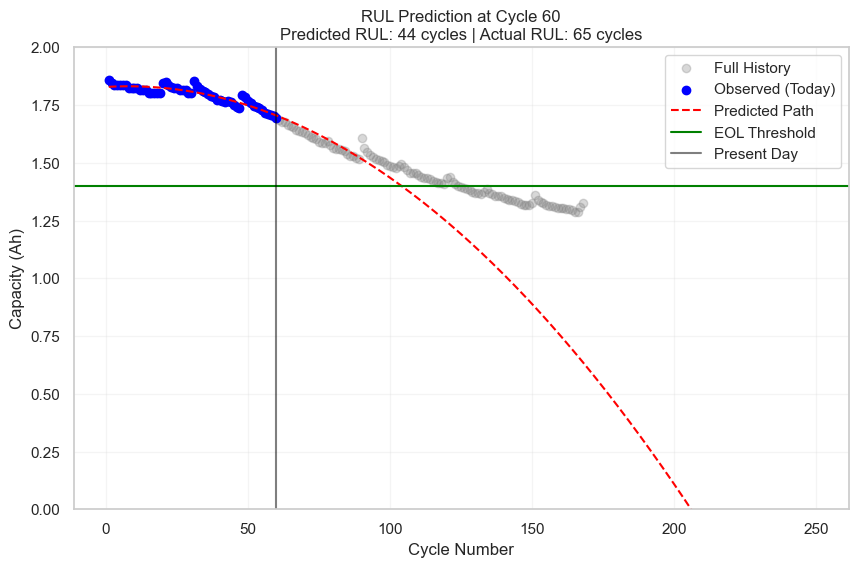

At Cycle 60:
The model says the battery has 44 cycles left.
In reality, the battery had 65 cycles left.


In [94]:
import scipy.io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Load Data
path = os.path.join(os.getcwd(), '1. BatteryAgingARC-FY08Q4/B0005.mat')
mat = scipy.io.loadmat(path)
cycles = mat['B0005'][0, 0]['cycle'][0]

capacity, cycle_id = [], []
for i, cycle in enumerate(cycles):
    if cycle['type'][0] == 'discharge':
        capacity.append(cycle['data'][0, 0]['Capacity'][0, 0])
        cycle_id.append(len(cycle_id) + 1)

df = pd.DataFrame({'Cycle': cycle_id, 'Capacity': capacity})

print("df head:\n", df.head())

# 2. Setup the "Present Day" (Predicting from Cycle 80)
current_cycle = 60
X_observed = df[['Cycle']].iloc[:current_cycle].values
y_observed = df['Capacity'].iloc[:current_cycle].values

# 3. Train a Polynomial Model (Degree 2 for the "curve")
poly = PolynomialFeatures(degree=2)
model = LinearRegression()
model.fit(poly.fit_transform(X_observed), y_observed)

# 4. Forecast the Future
# We predict up to 250 cycles to find where it hits 1.4Ah
X_future = np.array(range(1, 250)).reshape(-1, 1)
# print("X_future shape:", X_future)
y_future = model.predict(poly.transform(X_future))
# print("y_future shape:", y_future)
# Find the Predicted Failure Cycle
pred_failure_idx = np.where(y_future <= 1.4)[0]
pred_failure_cycle = X_future[pred_failure_idx[0]][0] if len(pred_failure_idx) > 0 else 0
predicted_rul = pred_failure_cycle - current_cycle

# Find the Actual Failure Cycle (from the full dataset)
actual_failure_df = df[df['Capacity'] <= 1.4]
actual_failure_cycle = actual_failure_df['Cycle'].iloc[0] if not actual_failure_df.empty else 0
actual_rul = actual_failure_cycle - current_cycle

# 5. Plotting
plt.figure(figsize=(10, 6))
plt.scatter(df['Cycle'], df['Capacity'], color='gray', alpha=0.3, label='Full History')
plt.scatter(df['Cycle'][:current_cycle], df['Capacity'][:current_cycle], color='blue', label='Observed (Today)')
plt.plot(X_future, y_future, color='red', linestyle='--', label='Predicted Path')

# Mark the points
plt.axhline(1.4, color='green', linestyle='-', label='EOL Threshold')
plt.axvline(current_cycle, color='black', alpha=0.5, label='Present Day')

plt.title(f"RUL Prediction at Cycle {current_cycle}\nPredicted RUL: {predicted_rul} cycles | Actual RUL: {actual_rul} cycles")
plt.xlabel("Cycle Number")
plt.ylabel("Capacity (Ah)")
plt.ylim(0.0, 2.0)
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

print(f"At Cycle {current_cycle}:")
print(f"The model says the battery has {predicted_rul} cycles left.")
print(f"In reality, the battery had {actual_rul} cycles left.")

## State of Charge (SOC)

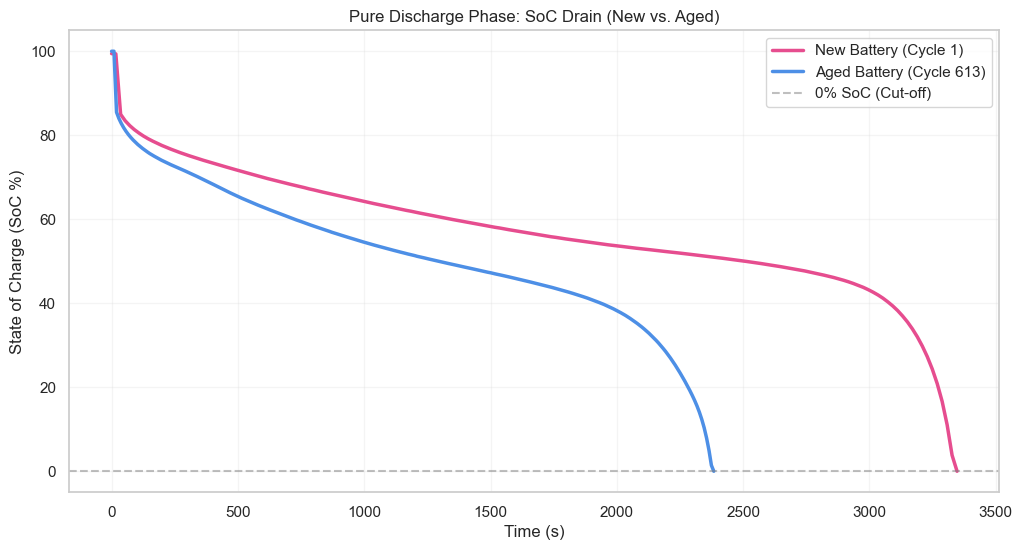

New Battery reached 0% SoC at approximately 3347 seconds.
Aged Battery reached 0% SoC at approximately 2384 seconds.


In [102]:
import scipy.io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Load Data
path = os.path.join(os.getcwd(), '1. BatteryAgingARC-FY08Q4/B0005.mat')
mat = scipy.io.loadmat(path)
cycles = mat['B0005'][0, 0]['cycle'][0]

# 2. Identify First and Last Discharge Indices
discharge_indices = [i for i, c in enumerate(cycles) if c['type'][0] == 'discharge']
first_idx = discharge_indices[0]
last_idx = discharge_indices[-1]

# 3. Function to Extract "Discharge Only" SoC Data
def get_discharge_soc(cycle_index):
    data = cycles[cycle_index]['data'][0, 0]
    voltage = data['Voltage_measured'][0]
    time = data['Time'][0]
    
    # --- THE CUT-OFF LOGIC ---
    # We find the index where voltage is at its minimum
    # This is exactly when the load stops and recovery begins
    stop_idx = np.argmin(voltage)
    
    # Only keep data up to that stop point
    v_cut = voltage[:stop_idx + 1]
    t_cut = time[:stop_idx + 1]
    
    # Linear Mapping: 4.2V = 100%, 2.7V = 0%
    v_max, v_min = 4.2, 2.7
    soc = ((v_cut - v_min) / (v_max - v_min)) * 100
    soc = np.clip(soc, 0, 100)
    
    return t_cut, soc

# 4. Get Data
time_new, soc_new = get_discharge_soc(first_idx)
time_old, soc_old = get_discharge_soc(last_idx)

# 5. Plotting
plt.figure(figsize=(12, 6))

plt.plot(time_new, soc_new, color='#e64d8f', linewidth=2.5, label=f'New Battery (Cycle {first_idx})')
plt.plot(time_old, soc_old, color='#4d8fe6', linewidth=2.5, label=f'Aged Battery (Cycle {last_idx})')

# Styling
plt.axhline(y=0, color='gray', linestyle='--', alpha=0.5, label='0% SoC (Cut-off)')
plt.xlabel('Time (s)')
plt.ylabel('State of Charge (SoC %)')
plt.title('Pure Discharge Phase: SoC Drain (New vs. Aged)')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()
print(f"New Battery reached 0% SoC at approximately {time_new[-1]:.0f} seconds.")
print(f"Aged Battery reached 0% SoC at approximately {time_old[-1]:.0f} seconds.")

## SOC prediction

Performing State of Charge (SOC) prediction is more complex than SOH because SOC changes rapidly every second, whereas SOH changes slowly over months. In the NASA dataset, we primarily use Voltage, Current, and Temperature as the "features" to guess the SOC.


### Machine Learning (Regression) based SOC prediction: 

- Features ($X$): Voltage, Current, Temperature.
- Target ($y$): SOC %.

Learning algorithm: Multi-variable Linear regression.


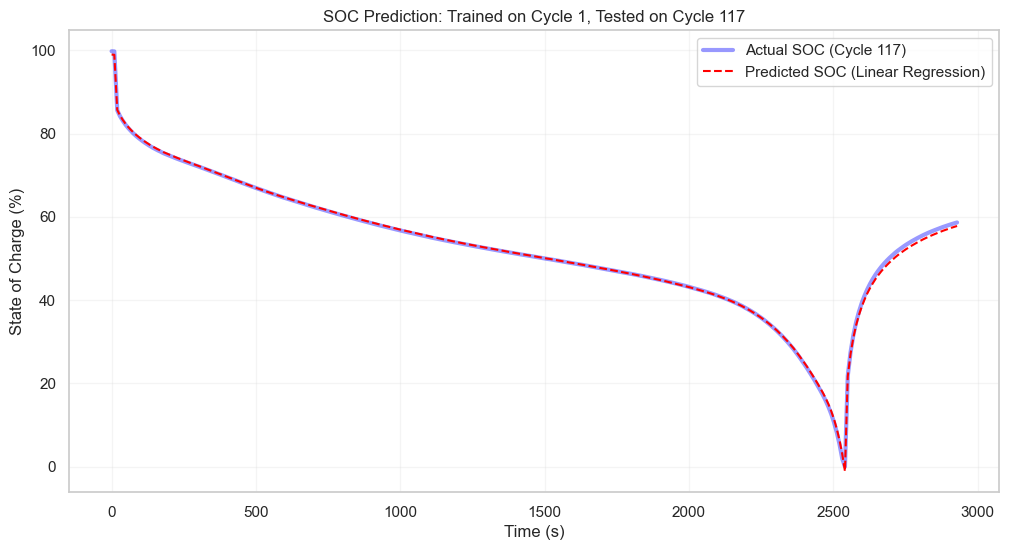

Mean Absolute Error: 0.2514%


In [127]:
import scipy.io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# 1. Identify first and second discharge cycles
discharge_indices = [i for i, c in enumerate(cycles) if c['type'][0] == 'discharge']
first_cycle = 0
second_cycle = 116
idx_train = discharge_indices[first_cycle] # First Cycle
idx_test = discharge_indices[second_cycle]  # Second Cycle

# 2. Helper function to prepare X (features) and y (target SOC)
def prepare_data(cycle_idx):
    data = cycles[cycle_idx]['data'][0, 0]
    
    # Features: Voltage, Current, Temperature
    X = pd.DataFrame({
        'Voltage': data['Voltage_measured'][0],
        'Current': data['Current_measured'][0],
        'Temp': data['Temperature_measured'][0]
    })
    
    # Target: Ground Truth SOC (Mapped 2.7V - 4.2V to 0 - 100%)
    y = ((X['Voltage'] - 2.7) / (4.2 - 2.7)) * 100
    y = np.clip(y, 0, 100)
    
    return X, y, data['Time'][0]

# Prepare Training and Testing sets
X_train, y_train, time_train = prepare_data(idx_train)
X_test, y_test, time_test = prepare_data(idx_test)

# 3. Train the Random Forest Model
# n_estimators=100 means we are using 100 "decision trees" to vote on the answer
# model = RandomForestRegressor(n_estimators=100, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Predict SOC for the Second Cycle
y_pred = model.predict(X_test)

# 5. Plotting the Comparison
plt.figure(figsize=(12, 6))

plt.plot(time_test, y_test, label=f'Actual SOC (Cycle {second_cycle + 1})', color='blue', linewidth=3, alpha=0.4)
plt.plot(time_test, y_pred, label='Predicted SOC (Linear Regression)', color='red', linestyle='--')

plt.xlabel('Time (s)')
plt.ylabel('State of Charge (%)')
plt.title(f'SOC Prediction: Trained on Cycle {first_cycle + 1}, Tested on Cycle {second_cycle + 1}')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

# 6. Performance Metric
mae = mean_absolute_error(y_test, y_pred)
print(f"Mean Absolute Error: {mae:.4f}%")